<a href="https://colab.research.google.com/github/xquynhtrinh/ME-238-Final-Project/blob/main/ME_238_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset

In [ ]:
from google.colab import drive
import shutil

drive.mount('/content/drive')

# Zip the Casting-10 dataset directly into your Google Drive
shutil.make_archive('/content/drive/MyDrive/Casting-10', 'zip', '/content/Casting-10')
print("Saved Casting-10.zip to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved Casting-10.zip to Google Drive!


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="MPnWWgwQJq2xqCzdblAU")
project = rf.workspace("new-workspace-kmz9b").project("casting")
version = project.version(10)
dataset = version.download("yolov11")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 144.1 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Casting-10 in yolov11:: 100%|██████████| 4898/4898 [00:00<00:00, 5927.52it/s]


Install ultralytics

In [ ]:
!pip install ultralytics

import yaml
from ultralytics import YOLO

# Verify the dataset path and classes (cast_ok, cast_def)
yaml_path = f"{dataset.location}/data.yaml"
with open(yaml_path, 'r') as f:
    data_config = yaml.safe_load(f)
print(data_config)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 13.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 7, 'names': ['casting_with_burr', 'crack', 'pit', 'polished_casting', 'scratch', 'stain', 'unpolished_casting'], 'roboflow': {'workspace': 'new-workspace-kmz9b', 'project': 'casting', 'version': 10, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/new-workspace-kmz9b/casting/dataset/10'}}


Train baseline yolov11

In [ ]:
# Load a pretrained YOLOv11 nano or small model for fast real-time inference
baseline_model = YOLO("yolo11n.pt")

# Train baseline model
baseline_results = baseline_model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    name="casting_yolov11_baseline"
)

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Casting-10/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=casting_yolov11_baseline, nbs=64, nms=None, opset=None, opti

Train with factory lighting & geometric augmentations

In [ ]:
aug_model = YOLO("yolo11n.pt")

# Train with lighting (HSV-Value) and geometric augmentations
aug_results = aug_model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    hsv_h=0.015,  # Hue adjustment
    hsv_s=0.5,    # Saturation adjustment
    hsv_v=0.6,    # Brightness/contrast scaling to simulate factory floor lighting
    degrees=15.0, # Random rotation
    flipud=0.5,   # Vertical flip
    fliplr=0.5,   # Horizontal flip
    name="casting_yolov11_augmented"
)

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Casting-10/data.yaml, degrees=15.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.6, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=casting_yolov11_augmented, nbs=64, nms=None, opset=None, op

Evaluate metrics, latency, and confusion matrix

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1052.6±445.4 MB/s, size: 25.3 KB)
val: Scanning /content/Casting-10/test/labels.cache... 255 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 255/255 107.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.5it/s 4.6s
                   all        255        670      0.893      0.876      0.914      0.642
     casting_with_burr         54         54      0.971          1      0.994      0.953
                 crack        157        184      0.897      0.849      0.924      0.413
                   pit         29         29       0.86          1      0.941      0.471
      polished_casting         36         36      0.916      0.972      0.981      0.981
               scratch        138        1

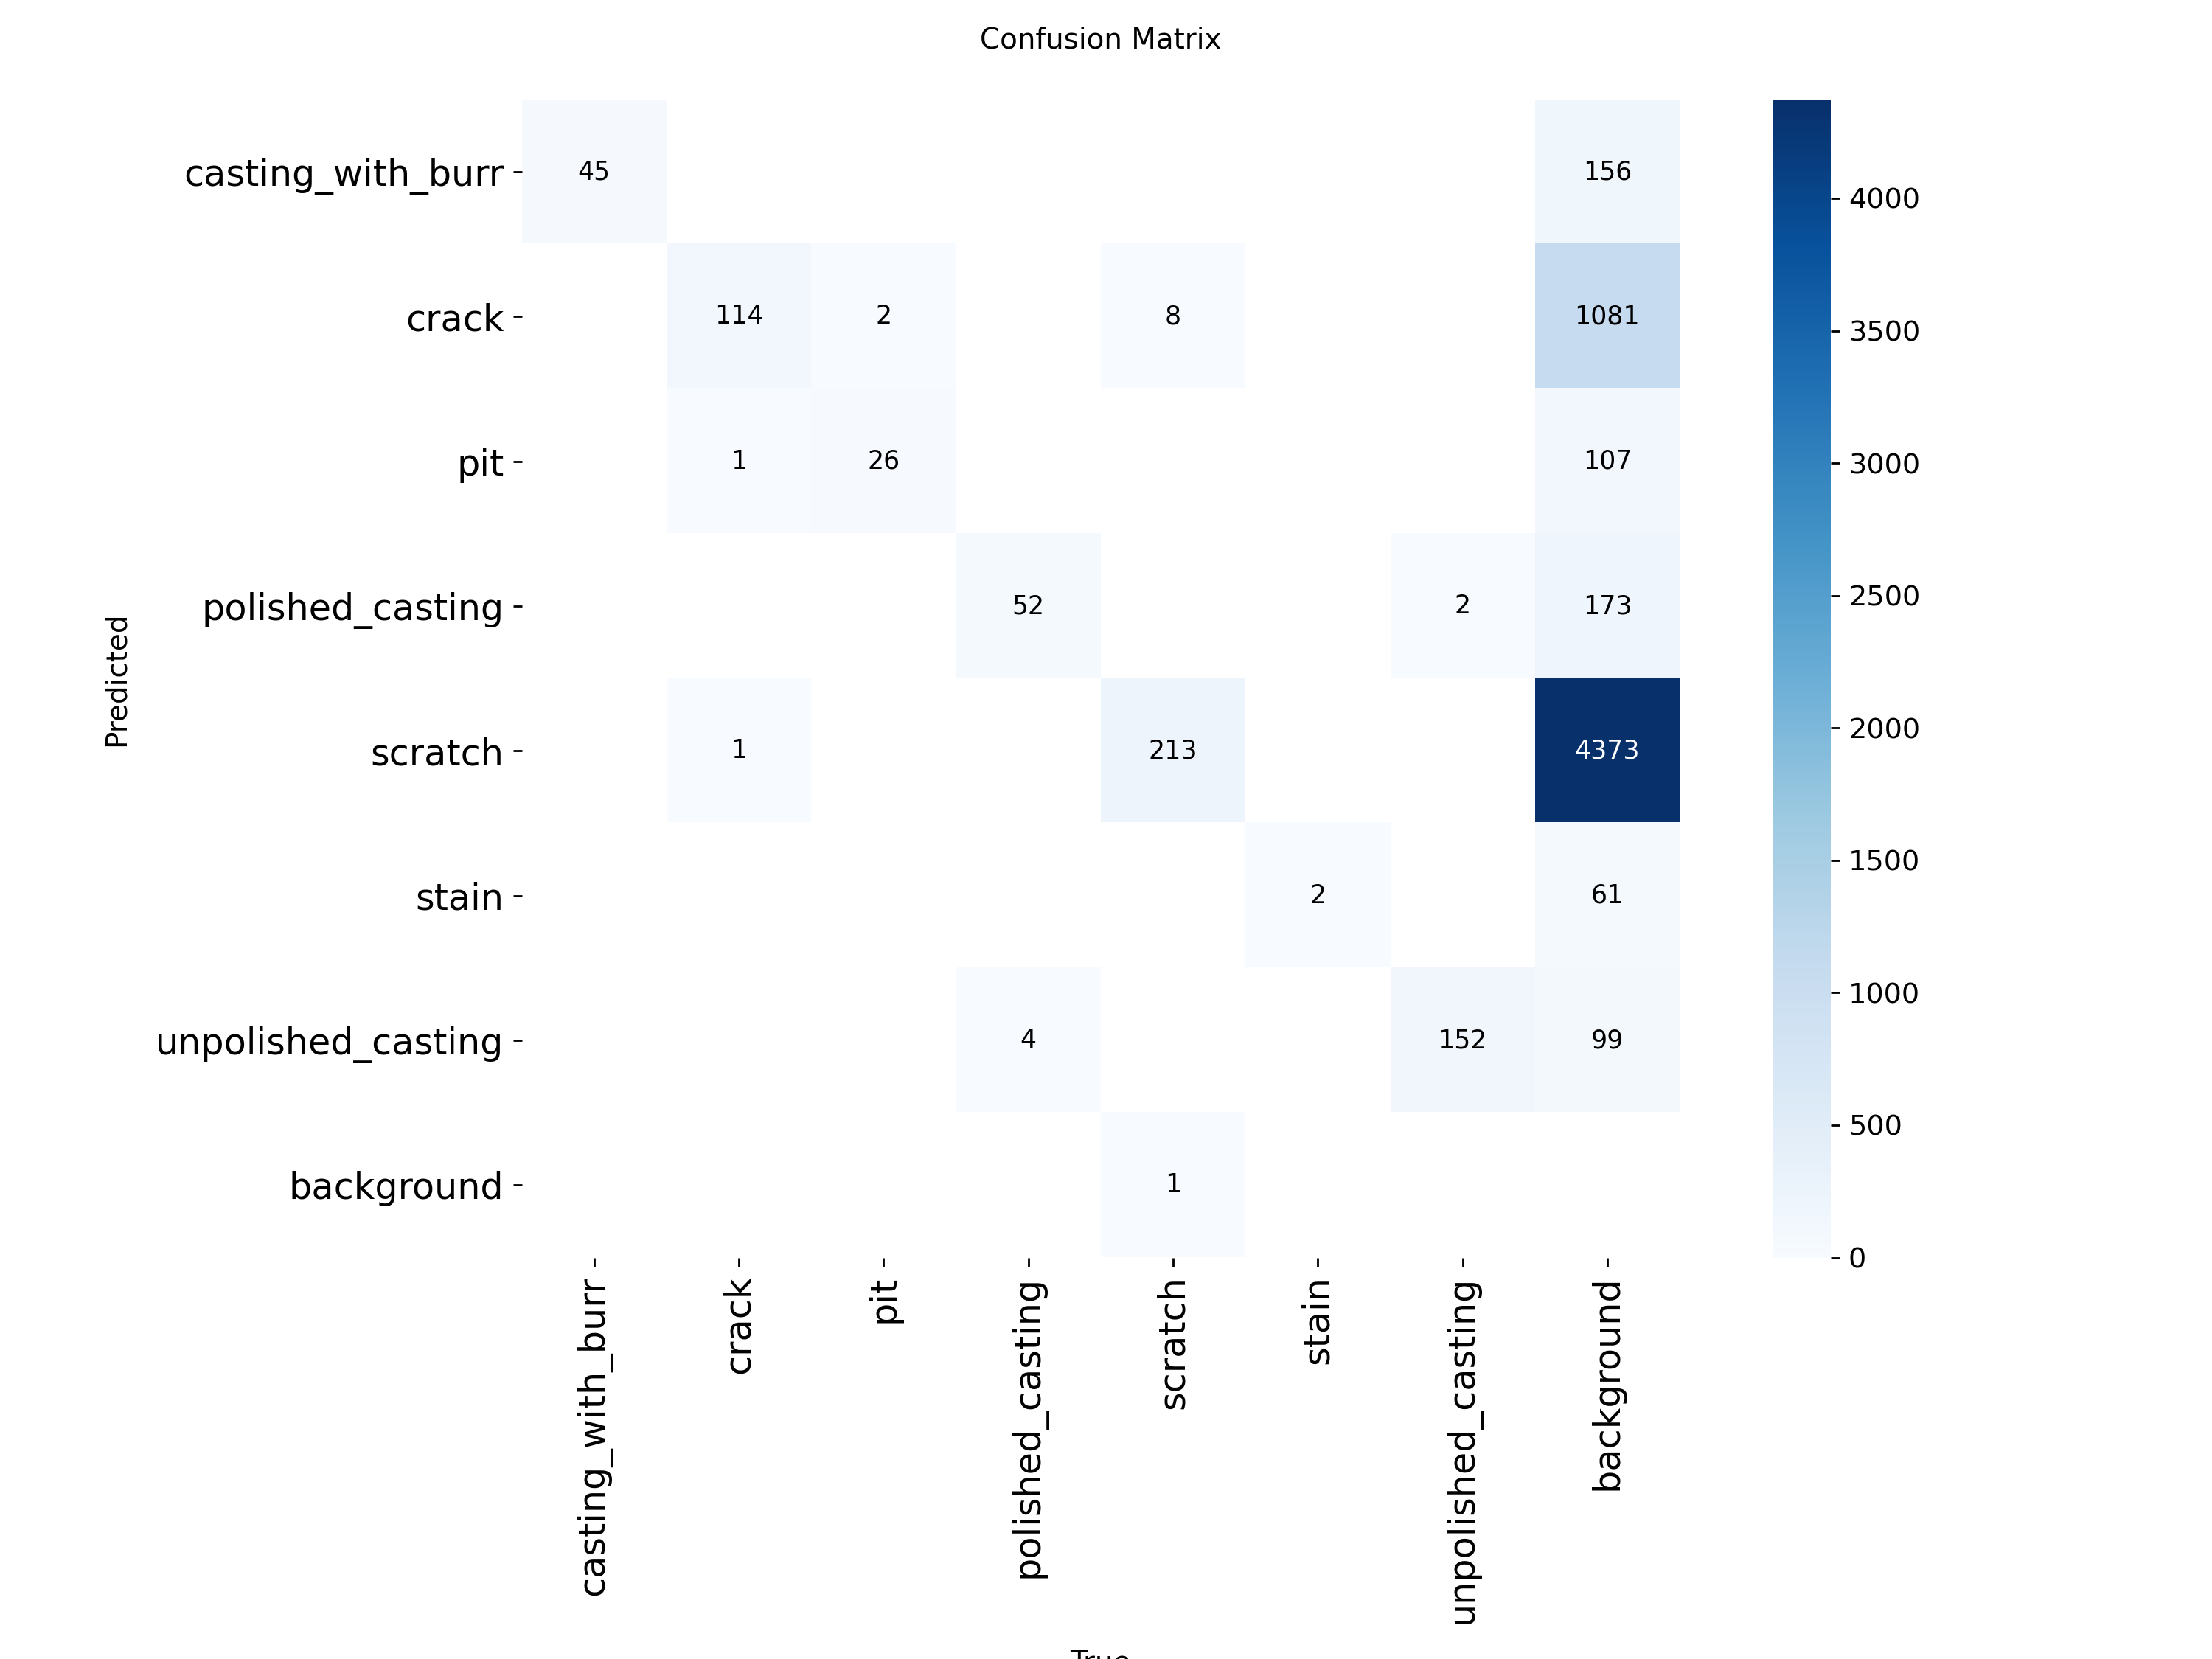

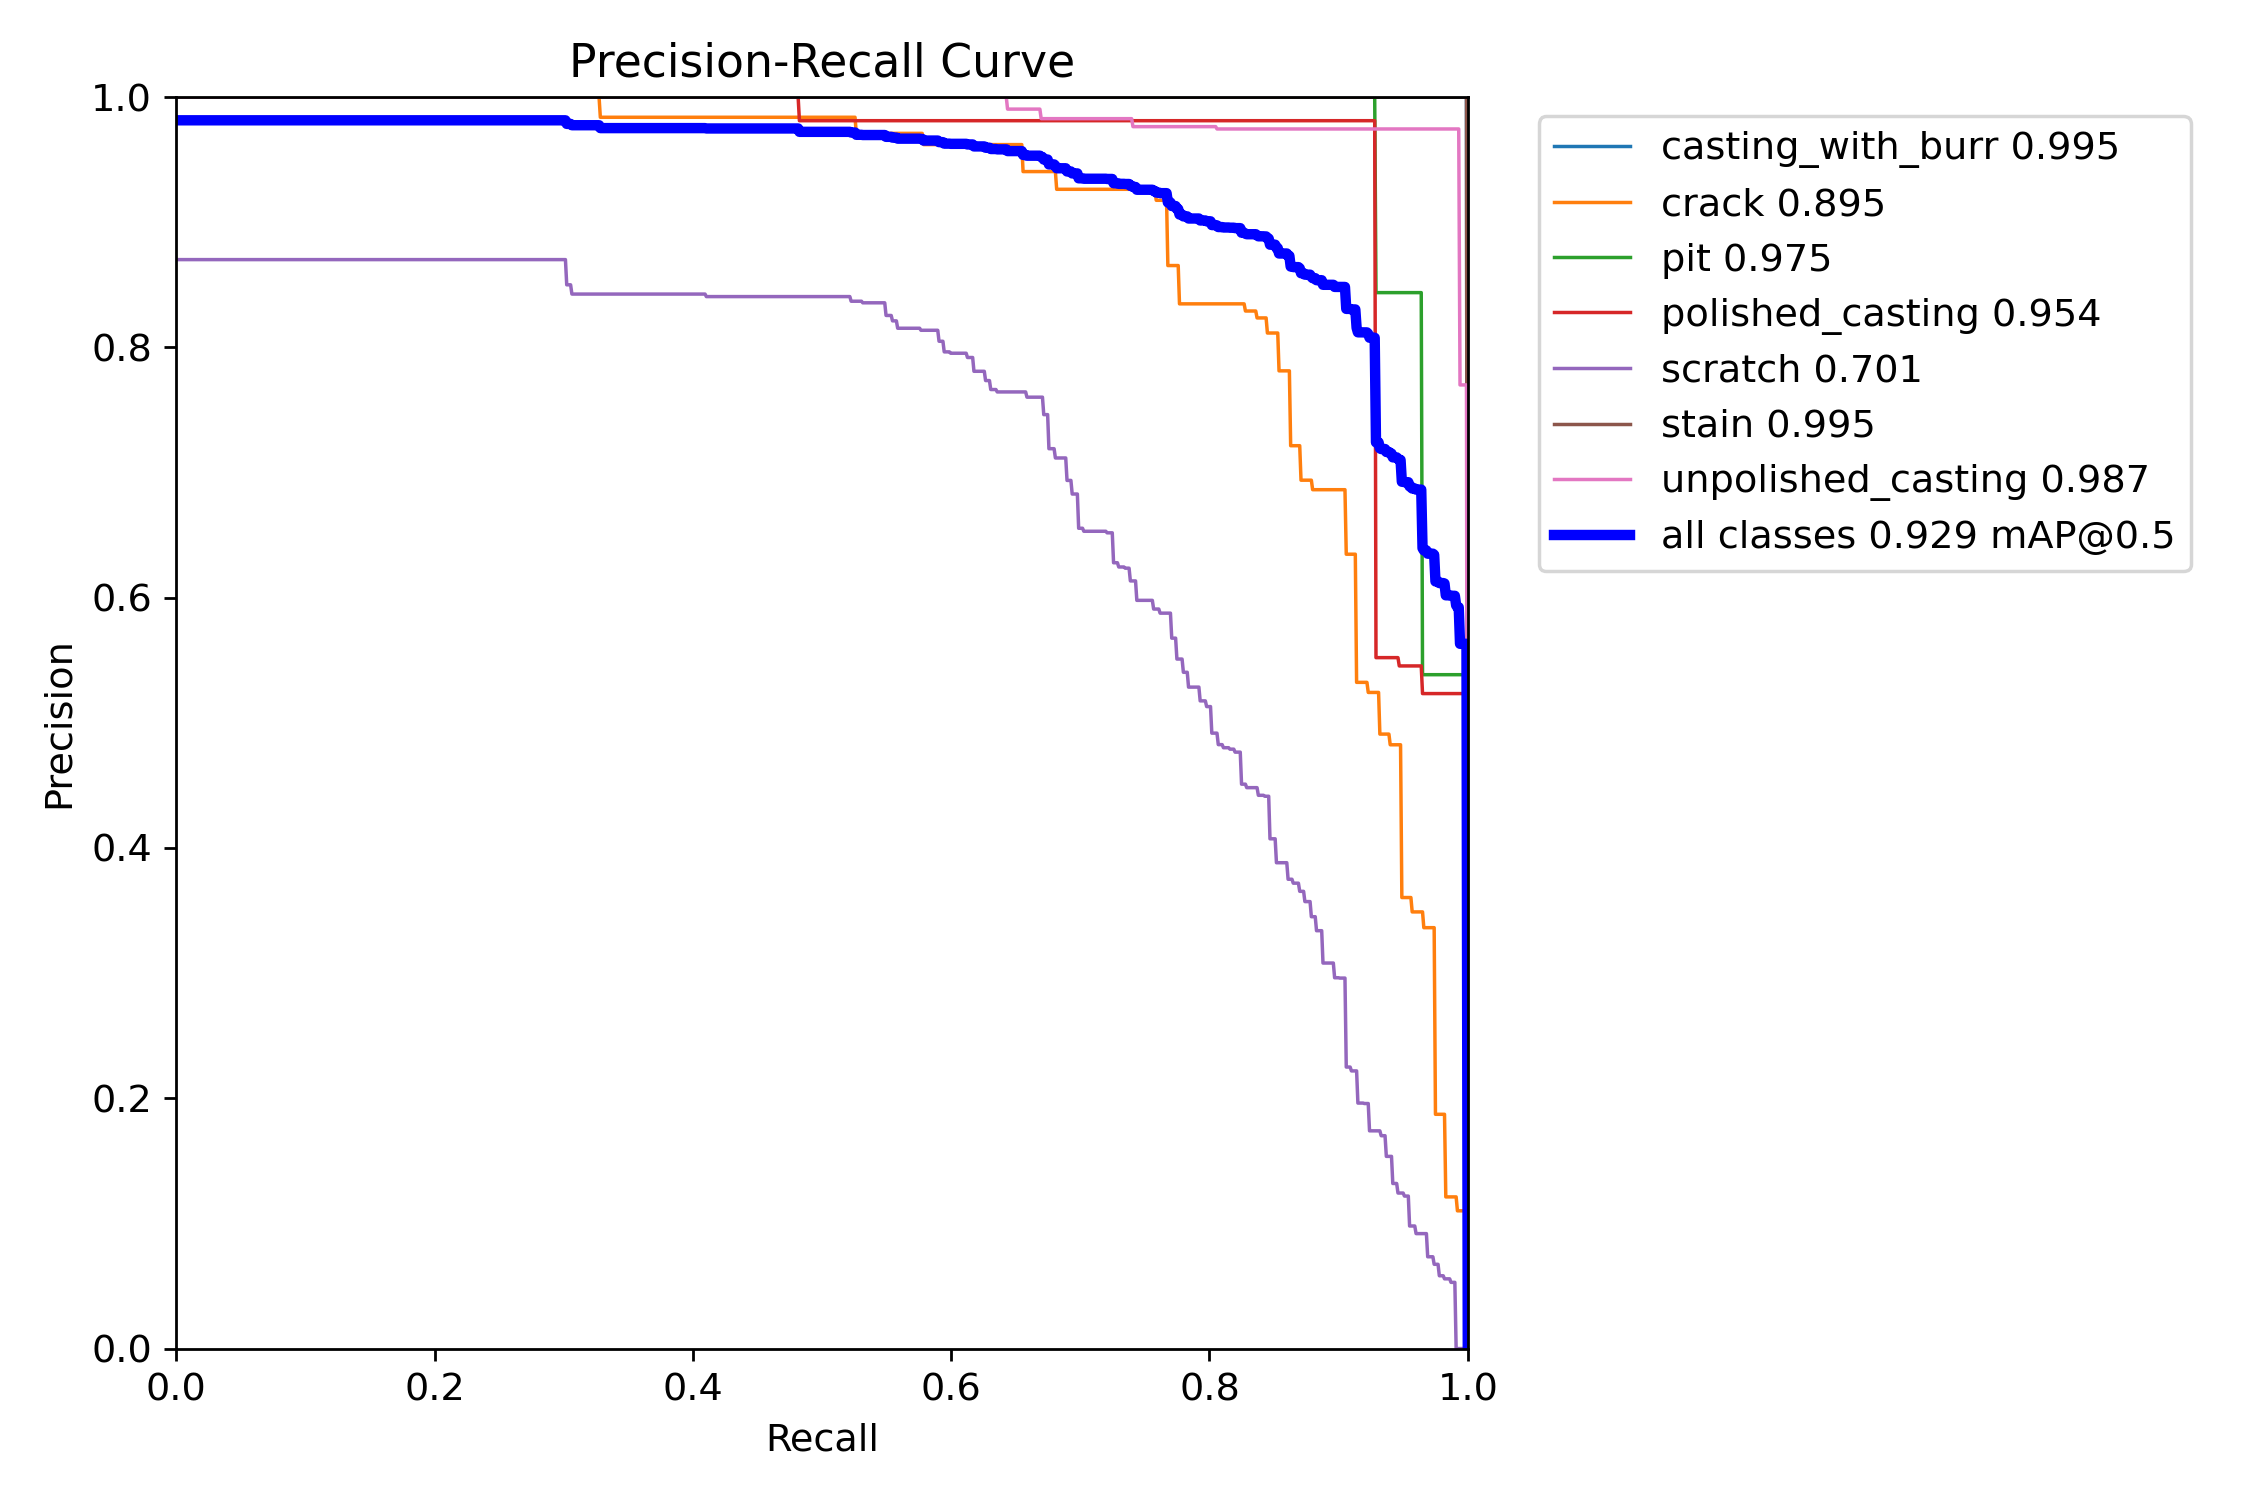

In [ ]:
# Evaluate on the test split
metrics = aug_model.val(data=yaml_path, split="test")

print(f"mAP50: {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"Inference speed (ms/image): {metrics.speed['inference']:.2f} ms")

# Display the generated Confusion Matrix and PR Curve
from IPython.display import Image, display
display(Image(filename="runs/detect/casting_yolov11_augmented/confusion_matrix.png", width=600))
display(Image(filename="runs/detect/casting_yolov11_augmented/BoxPR_curve.png", width=600))

False positive vs defect escapes

In [ ]:
import numpy as np

# Extract raw confusion matrix counts from validation metrics
cm = metrics.confusion_matrix.matrix
print("Raw Confusion Matrix:\n", cm)

# Define hypothetical manufacturing unit costs (adjust for your report)
cost_per_false_positive = 15.00   # Cost of scrapping/re-inspecting a good part ($)
cost_per_false_negative = 250.00  # Cost of a defective part escaping to the customer ($)

# Assuming index 0 = cast_def, index 1 = cast_ok (verify order from data_config['names'])
false_positives = cm[0, 1] # Predicted cast_def, actually cast_ok
false_negatives = cm[1, 0] # Predicted cast_ok, actually cast_def
total_parts = cm.sum()

fp_rate = (false_positives / total_parts) * 100
fn_rate = (false_negatives / total_parts) * 100
total_error_cost = (false_positives * cost_per_false_positive) + (false_negatives * cost_per_false_negative)

print(f"False Alarm Rate (Scrap Risk): {fp_rate:.2f}% ({int(false_positives)} parts)")
print(f"Defect Escape Rate (Safety/Quality Risk): {fn_rate:.2f}% ({int(false_negatives)} parts)")
print(f"Estimated Cost of Inspection Errors on Test Batch: ${total_error_cost:.2f}")

Raw Confusion Matrix:
 [[         54           0           0           0           1           0           0         165]
 [          0         176           0           0           4           1           0        1209]
 [          0           3          29           0           0           0           0         151]
 [          0           0           0          35           0           0           1         183]
 [          0           5           0           0         193           0           0        4617]
 [          0           0           0           0           0           3           0          71]
 [          0           0           0           1           0           0         163          92]
 [          0           0           0           0           1           0           0           0]]
False Alarm Rate (Scrap Risk): 0.00% (0 parts)
Defect Escape Rate (Safety/Quality Risk): 0.00% (0 parts)
Estimated Cost of Inspection Errors on Test Batch: $0.00


Fix multi-class error breakdown

In [ ]:
import numpy as np

cm = metrics.confusion_matrix.matrix

# Class indices based on data_config['names']
defect_idx = [0, 1, 2, 4, 5]  # burr, crack, pit, scratch, stain
ok_idx = [3, 6]               # polished_casting, unpolished_casting
bg_idx = [7]                  # background (missed detection or false background alarm)

# Rows = Predicted, Columns = True
# False Positives: True is OK (or background), Predicted is Defect
fp_ok_as_defect = cm[np.ix_(defect_idx, ok_idx)].sum()
fp_bg_as_defect = cm[np.ix_(defect_idx, bg_idx)].sum()
false_positives = fp_ok_as_defect + fp_bg_as_defect

# False Negatives: True is Defect, Predicted is OK or missed (Background)
fn_defect_as_ok = cm[np.ix_(ok_idx, defect_idx)].sum()
fn_defect_missed = cm[np.ix_(bg_idx, defect_idx)].sum()
false_negatives = fn_defect_as_ok + fn_defect_missed

# Total ground-truth instances (sum of all true columns 0..6)
total_gt_instances = cm[:, :7].sum()

cost_per_fp = 15.00   # Scrap / re-inspection cost ($)
cost_per_fn = 250.00  # Defect escape cost ($)
total_cost = (false_positives * cost_per_fp) + (false_negatives * cost_per_fn)

print(f"Total Ground-Truth Instances: {int(total_gt_instances)}")
print(f"False Positives (Scrap Risk): {int(false_positives)} ({(false_positives/total_gt_instances)*100:.2f}%)")
print(f"  - Good part flagged as defect: {int(fp_ok_as_defect)}")
print(f"  - Background noise flagged as defect: {int(fp_bg_as_defect)}")
print(f"False Negatives (Defect Escapes): {int(false_negatives)} ({(false_negatives/total_gt_instances)*100:.2f}%)")
print(f"  - Defect misclassified as OK part: {int(fn_defect_as_ok)}")
print(f"  - Defect missed completely (background): {int(fn_defect_missed)}")
print(f"Estimated Total Error Cost: ${total_cost:,.2f}")

Total Ground-Truth Instances: 670
False Positives (Scrap Risk): 6213 (927.31%)
  - Good part flagged as defect: 0
  - Background noise flagged as defect: 6213
False Negatives (Defect Escapes): 1 (0.15%)
  - Defect misclassified as OK part: 0
  - Defect missed completely (background): 1
Estimated Total Error Cost: $93,445.00


Optimal Confidence Threshold: 0.05
Minimum Inspection Error Cost: $135.00 (FP: 9 parts, FN: 0 parts)


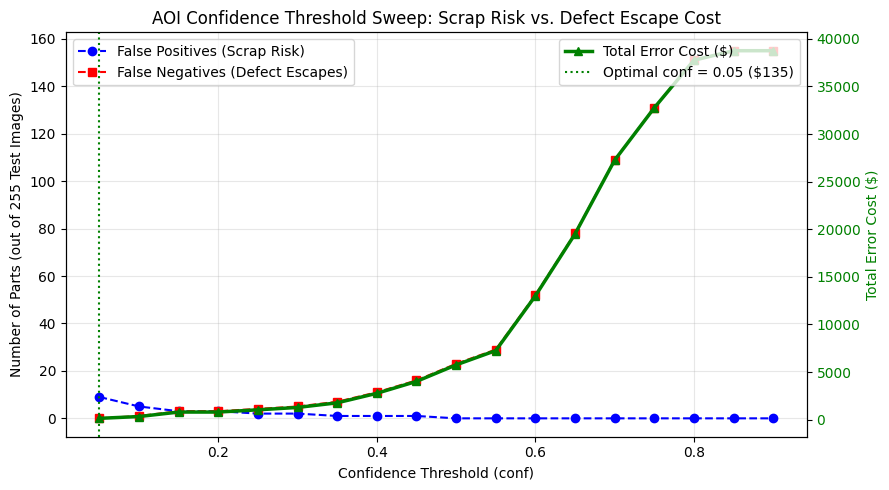

In [ ]:
import glob
import os
import numpy as np
import matplotlib.pyplot as plt

defect_idx = {0, 1, 2, 4, 5}
test_img_dir = f"{dataset.location}/test/images"
test_lbl_dir = f"{dataset.location}/test/labels"
test_images = sorted(glob.glob(f"{test_img_dir}/*.*"))

# 1. Run inference once on all test images with a low threshold
preds = aug_model.predict(source=test_images, conf=0.05, verbose=False)

# 2. Extract Ground Truth (Part is defective if any label in its .txt file is in defect_idx)
gt_is_defective = []
for img_path in test_images:
    base = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(test_lbl_dir, f"{base}.txt")
    has_defect = False
    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            for line in f:
                cls_id = int(line.split()[0])
                if cls_id in defect_idx:
                    has_defect = True
                    break
    gt_is_defective.append(has_defect)

gt_is_defective = np.array(gt_is_defective)

# 3. Sweep confidence thresholds from 0.05 to 0.90
thresholds = np.linspace(0.05, 0.90, 18)
fp_counts, fn_counts, total_costs = [], [], []

cost_per_fp = 15.00   # Cost of false rejection ($)
cost_per_fn = 250.00  # Cost of defect escape ($)

for thresh in thresholds:
    pred_is_defective = []
    for r in preds:
        cls_preds = r.boxes.cls.cpu().numpy().astype(int)
        conf_preds = r.boxes.conf.cpu().numpy()
        # Flag part as defective if any predicted defect box has conf >= thresh
        flagged = any((c in defect_idx) and (p >= thresh) for c, p in zip(cls_preds, conf_preds))
        pred_is_defective.append(flagged)

    pred_is_defective = np.array(pred_is_defective)

    fp = np.sum(pred_is_defective & (~gt_is_defective))
    fn = np.sum((~pred_is_defective) & gt_is_defective)
    cost = (fp * cost_per_fp) + (fn * cost_per_fn)

    fp_counts.append(fp)
    fn_counts.append(fn)
    total_costs.append(cost)

# Find optimal threshold
best_idx = int(np.argmin(total_costs))
best_thresh = thresholds[best_idx]
min_cost = total_costs[best_idx]

print(f"Optimal Confidence Threshold: {best_thresh:.2f}")
print(f"Minimum Inspection Error Cost: ${min_cost:,.2f} (FP: {fp_counts[best_idx]} parts, FN: {fn_counts[best_idx]} parts)")

# 4. Plot the Trade-Off and Cost Curve for your ME 238 Report
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(thresholds, fp_counts, 'b--o', label='False Positives (Scrap Risk)')
ax1.plot(thresholds, fn_counts, 'r--s', label='False Negatives (Defect Escapes)')
ax1.set_xlabel('Confidence Threshold (conf)')
ax1.set_ylabel('Number of Parts (out of 255 Test Images)')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(thresholds, total_costs, 'g-^', linewidth=2.5, label='Total Error Cost ($)')
ax2.axvline(best_thresh, color='green', linestyle=':', label=f'Optimal conf = {best_thresh:.2f} (${min_cost:.0f})')
ax2.set_ylabel('Total Error Cost ($)', color='green')
ax2.tick_params(axis='y', labelcolor='green')
ax2.legend(loc='upper right')

plt.title('AOI Confidence Threshold Sweep: Scrap Risk vs. Defect Escape Cost')
plt.tight_layout()
plt.show()

Compare baseline vs augmented model

In [ ]:
import pandas as pd

# Evaluate baseline model on the test split
base_test_metrics = baseline_model.val(data=yaml_path, split="test")

# Build a per-class comparison table (mAP50 and Recall)
class_names = [data_config['names'][i] for i in range(data_config['nc'])]

comparison_df = pd.DataFrame({
    "Class": class_names + ["ALL (Overall)"],
    "Baseline mAP50": list(base_test_metrics.box.ap50) + [base_test_metrics.box.map50],
    "Augmented mAP50": list(metrics.box.ap50) + [metrics.box.map50],
    "Baseline Recall": list(base_test_metrics.box.r) + [base_test_metrics.box.mr],
    "Augmented Recall": list(metrics.box.r) + [metrics.box.mr],
    "Baseline Precision": list(base_test_metrics.box.p) + [base_test_metrics.box.mp],
    "Augmented Precision": list(metrics.box.p) + [metrics.box.mp],
})

comparison_df["mAP50 Diff"] = comparison_df["Augmented mAP50"] - comparison_df["Baseline mAP50"]
print(comparison_df.round(4).to_string(index=False))

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 692.3±194.3 MB/s, size: 24.3 KB)
val: Scanning /content/Casting-10/test/labels.cache... 255 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 255/255 56.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.1it/s 5.1s
                   all        255        670      0.876      0.864      0.888      0.651
     casting_with_burr         54         54       0.91          1      0.991      0.985
                 crack        157        184      0.853      0.789      0.883       0.41
                   pit         29         29       0.83          1      0.912      0.489
      polished_casting         36         36          1      0.917      0.975      0.969
               scratch        138        199

Inspect challenging surface defects

Scratch (mAP50 = 0.720, Recall = 0.558) and stain (mAP50 = 0.845, Recall = 0.750) had the lowest detection performance compare to burr (.994) and pit (.941)



Found 9 False Positive images: [30, 188, 199, 205, 213, 227, 236, 244, 247]


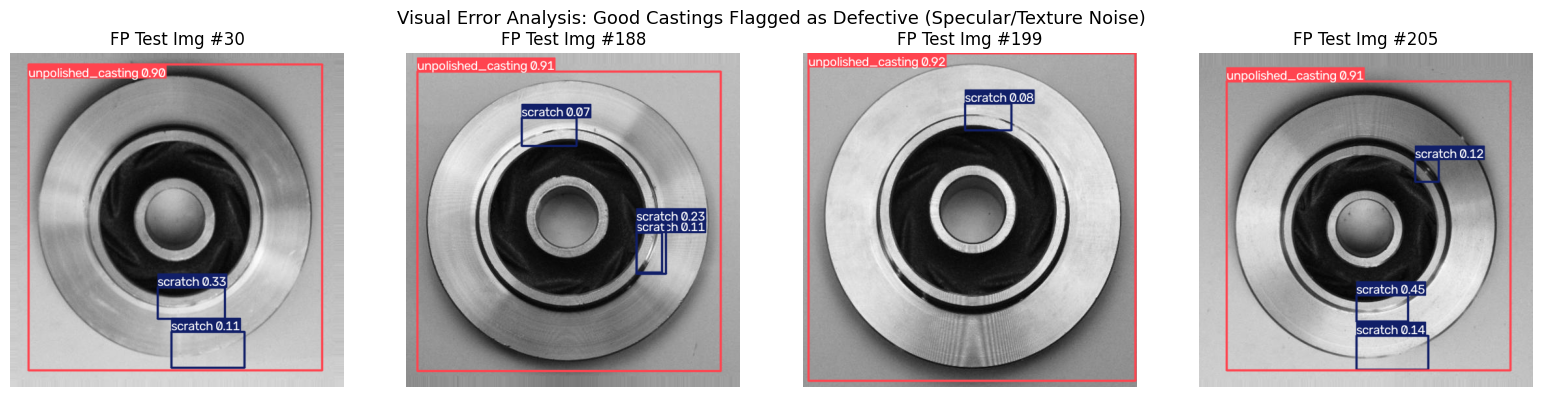

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Find indices of the 9 False Positive test images at optimal threshold (0.05)
fp_image_indices = []
for idx, (r, gt_def) in enumerate(zip(preds, gt_is_defective)):
    cls_preds = r.boxes.cls.cpu().numpy().astype(int)
    conf_preds = r.boxes.conf.cpu().numpy()
    flagged = any((c in defect_idx) and (p >= best_thresh) for c, p in zip(cls_preds, conf_preds))
    if flagged and not gt_def:
        fp_image_indices.append(idx)

print(f"Found {len(fp_image_indices)} False Positive images: {fp_image_indices}")

# Plot up to 4 False Positive images with predicted bounding boxes
fig, axes = plt.subplots(1, min(4, len(fp_image_indices)), figsize=(16, 4))
if len(fp_image_indices) == 1:
    axes = [axes]

for ax, img_idx in zip(axes, fp_image_indices[:4]):
    # Render predictions using the optimal threshold
    res_filtered = aug_model.predict(source=test_images[img_idx], conf=best_thresh, verbose=False)[0]
    im_bgr = res_filtered.plot()
    im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
    ax.imshow(im_rgb)
    ax.set_title(f"FP Test Img #{img_idx}")
    ax.axis("off")

plt.suptitle("Visual Error Analysis: Good Castings Flagged as Defective (Specular/Texture Noise)", fontsize=13)
plt.tight_layout()
plt.show()

Export trained weights and results

In [ ]:
import shutil
from google.colab import files

# Zip all training/validation runs (weights, confusion matrices, PR curves, loss plots)
shutil.make_archive("/content/ME238_YOLOv11_Results", "zip", "/content/runs")

# Download the zip file directly to your computer
files.download("/content/ME238_YOLOv11_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>